# Proyecto «Sala de crisis COVID-19» — notebook integral de los tres hitos

**Curso:** Gestión de Datos · IN1232C · Proyecto semestral
**Alcance de este notebook:** Hito 1 (exploración) + Hito 2 (plataforma) + Hito 3 (análisis, modelos y tablero)
**Fuentes:** Johns Hopkins CSSE (1.143 reportes diarios) · Our World in Data (vacunación) · Oxford OxCGRT (respuesta política)

Este notebook **cierra los tres hitos en un solo documento**: para cada hito explica en español **qué se hizo, por qué importa y con qué evidencia**, ejecuta el código real del proyecto (los módulos de `src/`) y muestra **tablas y gráficos rotulados en español**.

> **Reglas de oro del proyecto:** los acumulados publicados **no** son casos diarios; la fecha de cada observación es el **nombre del archivo** (`MM-DD-YYYY.csv`), no el campo `Last Update`; y un valor nulo **no** se convierte en cero.

### Qué corresponde a cada hito

| Hito | Qué se entrega | Dónde se demuestra aquí |
|---|---|---|
| **1 · Exploración** (hasta 10-nov) | Exploración de ene–jun 2020: inspección del primer reporte, nulos, estandarización, consolidación, top 10, serie de Chile, perfilado automático, tres observaciones y propuesta P7 | Sección «Hito 1» |
| **2 · Plataforma** (hasta 17-nov) | Descarga automatizada, unificación de esquemas, capa limpia Parquet, reglas de calidad ejecutables, DW en estrella e integración de fuentes externas | Sección «Hito 2» |
| **3 · Análisis y tablero** (hasta 18-nov) | P1–P6 con cifras y gráficos, P7 resuelta, segmentación, pronóstico sin fuga de datos, alerta evaluada y tablero con «Desafío en vivo» | Sección «Hito 3» |

### Cómo usar este notebook

1. **Ejecuta de arriba abajo** (`Kernel ▸ Run All`): cada celda depende de las anteriores.
2. **No reemplaza a `src/`**: este notebook *invoca* los módulos reales del proyecto (`calidad`, `modelos`, `p7_vacunacion`, `analisis_restricciones`) y resuelve el resto con consultas SQL sobre el almacén. Los scripts de `src/` siguen siendo el entregable reproducible.
3. **Si falta una capa**, la celda lo dice con claridad; el orden de reconstrucción está en el `README.md` (9 pasos numerados).
4. **Texto, tablas y gráficos en español.** Los nombres técnicos de columnas y archivos se conservan tal como vienen de la fuente (JHU) para que cualquier persona pueda cruzarlos con la fuente original.

In [1]:
# --- Preparación del entorno ------------------------------------------------
# Detecta la raíz del proyecto y agrega `src/` al path para importar los módulos
# reales del proyecto (calidad, modelos, P7, restricciones).
from datetime import date, datetime
from pathlib import Path
import sys

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Estilo de gráficos sobrio y consistente en todo el notebook.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

raices = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
ROOT = next((p for p in raices if (p / "src").is_dir() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abre Jupyter desde la carpeta Proyecto o desde Proyecto/notebooks.")
sys.path.insert(0, str(ROOT / "src"))

# Los modulos de `src/` usan rutas relativas a la raiz del proyecto
# (por ejemplo `data/dw/covid.duckdb`), asi que se trabaja desde alli.
import os
os.chdir(ROOT)

def restaurar_backend_interactivo() -> None:
    """Vuelve al backend 'inline' del notebook.

    Los modulos de `src/` fuerzan `matplotlib.use("Agg")` al importarse, porque
    alli se guardan las figuras en disco. En el notebook hay que restaurar el
    backend interactivo o las graficas dejan de mostrarse.
    """
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")


RAW_DIR = ROOT / "data" / "raw" / "daily_reports"
CLEAN_DIR = ROOT / "data" / "clean"
DW_PATH = ROOT / "data" / "dw" / "covid.duckdb"
REPORTS_DIR = ROOT / "reports"
DOCS_DIR = ROOT / "docs"

print(f"Raíz del proyecto: {ROOT}")
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · duckdb {duckdb.__version__}")

Raíz del proyecto: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto
Python 3.11.9 · pandas 2.3.3 · duckdb 2.0.0


---

## 0 · Estado de las tres capas del proyecto

La arquitectura tiene **tres capas** y cada una se regenera con un script del `README.md`. Esta tabla muestra, en el estado real de este repositorio, qué existe y qué habría que reconstruir.

In [2]:
# --- Comprobación del estado de cada capa -----------------------------------
def tamano_mb(ruta: Path) -> float:
    """Tamaño en MB de un archivo o de una carpeta completa (0 si no existe)."""
    if not ruta.exists():
        return 0.0
    if ruta.is_file():
        return ruta.stat().st_size / 1024 ** 2
    return sum(p.stat().st_size for p in ruta.rglob("*") if p.is_file()) / 1024 ** 2

capas = pd.DataFrame([
    {"Capa": "1 · Crudos (data/raw)", "Contenido": "1.143 reportes diarios, 5 series, tabla UID, OWID y OxCGRT",
     "Tamaño (MB)": tamano_mb(RAW_DIR.parent), "Se regenera con": "src/descargar_reportes.py"},
    {"Capa": "2 · Limpia (data/clean)", "Contenido": "Parquet unificado + tabla de territorios",
     "Tamaño (MB)": tamano_mb(CLEAN_DIR), "Se regenera con": "src/ingesta.py · src/territorios.py"},
    {"Capa": "3 · Almacén (data/dw)", "Contenido": "Modelo estrella en DuckDB (hechos + dimensiones)",
     "Tamaño (MB)": tamano_mb(DW_PATH), "Se regenera con": "src/construir_dw.py"},
])
capas["Estado"] = np.where(capas["Tamaño (MB)"] > 0, "Disponible", "FALTA: ejecutar el script")
display(capas.style.format({"Tamaño (MB)": "{:,.1f}"}).set_caption("Estado de las tres capas del proyecto"))

,Capa,Contenido,Tamaño (MB),Se regenera con,Estado
0,1 · Crudos (data/raw),"1.143 reportes diarios, 5 series, tabla UID, OWID y OxCGRT",648.0,src/descargar_reportes.py,Disponible
1,2 · Limpia (data/clean),Parquet unificado + tabla de territorios,110.2,src/ingesta.py · src/territorios.py,Disponible
2,3 · Almacén (data/dw),Modelo estrella en DuckDB (hechos + dimensiones),267.0,src/construir_dw.py,Disponible


---

# HITO 1 · Exploración inicial de datos (22-ene → 30-jun 2020)

**Qué se hizo:** antes de construir nada, se exploró una muestra pequeña y **rigurosa** del archivo de JHU para dejar documentados los cuatro problemas que condicionan todo el proyecto: **esquemas que cambian**, **nulos con significado**, **granularidad que varía** y **acumulados que no son casos diarios**.

**Por qué importa:** si estas cuatro cosas no se detectan aquí, el resto del proyecto (DW, calidad, modelos) nace sobre datos mal interpretados.

**Con qué evidencia:** las celdas siguientes reproducen la exploración completa sobre los 161 reportes del período, con tablas y gráfico en español.

### Hito 1 · 1.1 Inspección del primer reporte

Se lee `01-22-2020.csv` tal como lo publicó JHU y se revisan **dimensiones, tipos y nulos**. Los nombres de las columnas se traducen **solo para mostrar**; los datos no se tocan.

In [3]:
# --- Hito 1 · Inspección del primer reporte --------------------------------
primer_archivo = RAW_DIR / "01-22-2020.csv"
if not primer_archivo.exists():
    raise FileNotFoundError("Falta 01-22-2020.csv: ejecuta src/descargar_reportes.py")

primer_dia = pd.read_csv(primer_archivo)

# Traducción de rótulos para la presentación (los datos son los de JHU).
NOMBRES_ES = {
    "Province/State": "Provincia/Estado",
    "Country/Region": "País/Región",
    "Last Update": "Última actualización",
    "Confirmed": "Confirmados",
    "Deaths": "Fallecidos",
    "Recovered": "Recuperados",
}

display(primer_dia.head().rename(columns=NOMBRES_ES))
print(f"Dimensiones: {primer_dia.shape[0]:,} filas por {primer_dia.shape[1]} columnas")

tipos = primer_dia.dtypes.rename("tipo").rename(index=NOMBRES_ES).to_frame()
display(tipos)

nulos = pd.DataFrame({
    "nulos": primer_dia.isna().sum(),
    "porcentaje": (primer_dia.isna().mean() * 100).round(1),
}).rename(index=NOMBRES_ES).sort_values("nulos", ascending=False)
display(nulos)

,Provincia/Estado,País/Región,Última actualización,Confirmados,Fallecidos,Recuperados
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


Dimensiones: 76 filas por 6 columnas


,tipo
Provincia/Estado,object
País/Región,object
Última actualización,object
Confirmados,float64
Fallecidos,float64
Recuperados,float64


,nulos,porcentaje
Fallecidos,37,48.7
Recuperados,37,48.7
Provincia/Estado,12,15.8
Confirmados,10,13.2
País/Región,0,0.0
Última actualización,0,0.0


**Cómo se leen esos nulos** (es la explicación que pide el enunciado):

- `Provincia/Estado` vacío suele significar que el reporte es **a nivel país**, no que falte el país.
- `Confirmados`, `Fallecidos` o `Recuperados` nulos significan que **el reporte no entregó ese conteo**: no se imputan como cero.
- La **ausencia de una columna** en algunos reportes refleja cambios de esquema; al concatenar, pandas crea la columna y deja `NaN` en las fechas donde todavía no existía.

### Hito 1 · 1.2 Estandarización y consolidación (enero – junio de 2020)

Se normalizan los nombres de los distintos esquemas a `snake_case`, se conserva `last_update` como fecha (`AAAA-MM-DD`) y se deriva `report_date` **del nombre del archivo**. La concatenación alinea columnas y **conserva los nulos** donde un campo aún no existía.

In [4]:
# --- Hito 1 · Estandarización y consolidación -------------------------------
import re

ALIAS_COLUMNAS = {"latitude": "lat", "longitude": "long", "long_": "long"}


def estandarizar(df: pd.DataFrame) -> pd.DataFrame:
    """Normaliza los nombres de columna y la fecha de actualización de JHU."""
    df = df.copy()
    normalizadas = {}
    for nombre in df.columns:
        snake = re.sub(r"[^0-9a-zA-Z]+", "_", nombre.strip()).strip("_").lower()
        normalizadas[nombre] = ALIAS_COLUMNAS.get(snake, snake)
    df = df.rename(columns=normalizadas)
    if "last_update" in df.columns:
        df["last_update"] = pd.to_datetime(
            df["last_update"], format="mixed", errors="coerce", utc=True
        ).dt.strftime("%Y-%m-%d")
    return df


FECHA_INICIO, FECHA_FIN = date(2020, 1, 22), date(2020, 6, 30)
archivos = []
for archivo in RAW_DIR.glob("*.csv"):
    try:
        fecha_archivo = datetime.strptime(archivo.stem, "%m-%d-%Y").date()
    except ValueError:
        continue
    if FECHA_INICIO <= fecha_archivo <= FECHA_FIN:
        archivos.append((fecha_archivo, archivo))
archivos.sort(key=lambda elemento: elemento[0])
esperados = (FECHA_FIN - FECHA_INICIO).days + 1
print(f"Reportes del período: {len(archivos)} (se esperaban {esperados})")

frames, firmas = [], {}
for fecha_archivo, archivo in archivos:
    crudo = pd.read_csv(archivo)
    firma = tuple(crudo.columns)
    firmas.setdefault(firma, {"reportes": 0, "desde": fecha_archivo, "hasta": fecha_archivo})
    firmas[firma]["reportes"] += 1
    firmas[firma]["hasta"] = fecha_archivo
    diario = estandarizar(crudo)
    diario["report_date"] = pd.Timestamp(fecha_archivo)
    frames.append(diario)

consolidado = pd.concat(frames, ignore_index=True, sort=False)
print(f"Consolidado: {len(consolidado):,} filas x {consolidado.shape[1]} columnas; "
      f"{consolidado['report_date'].nunique()} fechas")

esquemas = pd.DataFrame([
    {"Esquema": i + 1, "Reportes": v["reportes"], "Desde": v["desde"], "Hasta": v["hasta"]}
    for i, v in enumerate(firmas.values())
]).sort_values("Desde", ignore_index=True)
display(esquemas)
print("Columnas estandarizadas:", ", ".join(consolidado.columns))

Reportes del período: 161 (se esperaban 161)


Consolidado: 350,945 filas x 15 columnas; 161 fechas


,Esquema,Reportes,Desde,Hasta
0,1,39,2020-01-22,2020-02-29
1,2,21,2020-03-01,2020-03-21
2,3,68,2020-03-22,2020-05-28
3,4,33,2020-05-29,2020-06-30


Columnas estandarizadas: province_state, country_region, last_update, confirmed, deaths, recovered, report_date, lat, long, fips, admin2, active, combined_key, incidence_rate, case_fatality_ratio


### Hito 1 · 1.3 Top 10 al 30 de junio y evolución de Chile

`confirmed` es **acumulado**. Para cada país y fecha se usa el **registro nacional** cuando existe y, solo si no existe, se **suman los registros subnacionales**: sin esta regla, Chile aparecería duplicado (fila nacional + 16 regiones).

,Casos confirmados acumulados
País/Región,
US,"2,653,658"
Brazil,"1,412,669"
Russia,"646,929"
India,"585,493"
United Kingdom,"314,157"
Peru,"285,213"
Chile,"279,393"
Spain,"249,271"
Italy,"240,578"


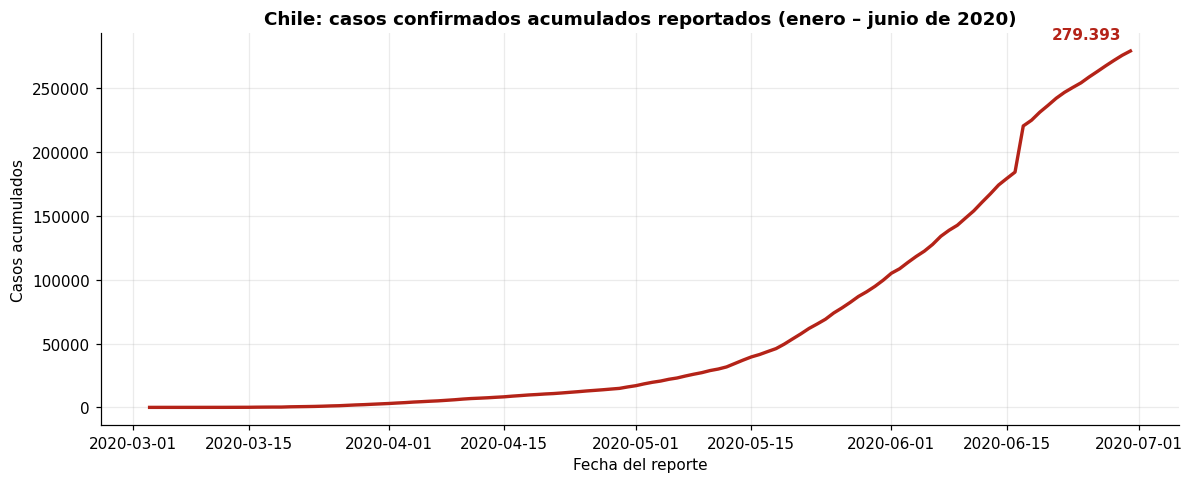

In [5]:
# --- Hito 1 · Top 10 al 30 de junio y serie de Chile ------------------------
columnas_geo = [c for c in ("province_state", "admin2") if c in consolidado.columns]
es_subnacional = consolidado[columnas_geo].notna().any(axis=1)
claves = ["report_date", "country_region"]

nacionales = consolidado.loc[~es_subnacional].groupby(claves)["confirmed"].max()
subnacionales = consolidado.loc[es_subnacional].groupby(claves)["confirmed"].sum(min_count=1)
totales = nacionales.combine_first(subnacionales).rename("confirmed")

corte = pd.Timestamp("2020-06-30")
top10 = (totales.xs(corte, level="report_date").dropna()
         .sort_values(ascending=False).head(10)
         .rename("Casos confirmados acumulados").to_frame())
top10.index.name = "País/Región"
display(top10.style.format("{:,.0f}").set_caption("Top 10 de casos confirmados acumulados al 30 de junio de 2020"))

serie_chile = totales.xs("Chile", level="country_region").dropna().sort_index()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(serie_chile.index, serie_chile.values, color="#b42318", linewidth=2.2)
ax.set_title("Chile: casos confirmados acumulados reportados (enero – junio de 2020)", weight="bold")
ax.set_xlabel("Fecha del reporte")
ax.set_ylabel("Casos acumulados")
ax.annotate(f"{serie_chile.iloc[-1]:,.0f}".replace(",", "."),
            xy=(serie_chile.index[-1], serie_chile.iloc[-1]),
            xytext=(-6, 8), textcoords="offset points", ha="right", color="#b42318", weight="bold")
fig.tight_layout()
plt.show()

### Hito 1 · 1.4 Perfilado automático y las tres observaciones

El perfilado se genera como HTML (`reports/perfil_enero_junio_2020.html`) y las tres observaciones se **calculan** desde el subconjunto exacto del Hito 1, para poder presentarlas sin depender de notas a mano.

In [6]:
# --- Hito 1 · Perfilado automático y observaciones --------------------------
import contextlib
import io
import warnings

warnings.filterwarnings("ignore")
from ydata_profiling import ProfileReport

perfil_path = REPORTS_DIR / "perfil_enero_junio_2020.html"
perfil = ProfileReport(
    consolidado,
    title="Perfil exploratorio COVID-19 – 22 ene a 30 jun 2020",
    minimal=True,
    progress_bar=False,
)
# Se captura la barra de progreso para no ensuciar la salida del notebook.
with contextlib.redirect_stderr(io.StringIO()):
    perfil.to_file(perfil_path)
print(f"Perfil HTML generado: {perfil_path} ({perfil_path.stat().st_size / 1024**2:.1f} MB)")

Perfil HTML generado: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto\reports\perfil_enero_junio_2020.html (3.0 MB)


In [7]:
# --- Hito 1 · Las tres observaciones del enunciado -------------------------
filas_por_fecha = consolidado.groupby("report_date").size()
porcentaje_nulos = consolidado.isna().mean().mul(100)
chile_filas = consolidado.loc[consolidado["country_region"].eq("Chile")].groupby("report_date").size()
cambio_nivel = chile_filas[chile_filas.ne(chile_filas.shift())]

print("OBSERVACIÓN 1 – El primer reporte ya viene incompleto")
print(
    f"El 22-ene-2020 hay {len(primer_dia)} filas y {primer_dia.shape[1]} columnas. "
    f"Nulos destacados: Provincia/Estado={primer_dia['Province/State'].isna().sum()}, "
    f"Confirmados={primer_dia['Confirmed'].isna().sum()}, "
    f"Fallecidos={primer_dia['Deaths'].isna().sum()}, "
    f"Recuperados={primer_dia['Recovered'].isna().sum()}."
)
print("Lectura: un nulo geográfico puede ser el total nacional; un nulo de conteo NO es cero.\n")

OBSERVACIÓN 1 – El primer reporte ya viene incompleto
El 22-ene-2020 hay 76 filas y 6 columnas. Nulos destacados: Provincia/Estado=12, Confirmados=10, Fallecidos=37, Recuperados=37.
Lectura: un nulo geográfico puede ser el total nacional; un nulo de conteo NO es cero.



In [8]:
print("OBSERVACIÓN 2 – Esquema y completitud")
print(
    f"Se consolidaron {len(consolidado):,} filas en {consolidado['report_date'].nunique()} días "
    f"y {len(firmas)} esquemas originales. Los reportes diarios varían entre "
    f"{filas_por_fecha.min():,} y {filas_por_fecha.max():,} filas."
)
for columna in ("incident_rate", "case_fatality_ratio"):
    if columna in porcentaje_nulos.index:
        print(f"  - {columna}: {porcentaje_nulos[columna]:.1f} % nulo; aparece en una etapa posterior, no se imputa.")
print()

OBSERVACIÓN 2 – Esquema y completitud
Se consolidaron 350,945 filas en 161 días y 4 esquemas originales. Los reportes diarios varían entre 76 y 3,824 filas.
  - case_fatality_ratio: 65.4 % nulo; aparece en una etapa posterior, no se imputa.



In [9]:
print("OBSERVACIÓN 3 – Cambio de granularidad en Chile")
if not cambio_nivel.empty:
    fecha_cambio = cambio_nivel.index[-1]
    print(
        f"Chile pasa de {int(chile_filas.iloc[0])} fila nacional el {chile_filas.index[0]:%d-%b-%Y} "
        f"a {int(chile_filas.loc[fecha_cambio])} filas regionales el {fecha_cambio:%d-%b-%Y}. "
        f"Al 30-jun-2020 suma {serie_chile.loc[pd.Timestamp('2020-06-30')]:,.0f} casos acumulados "
        "con la regla anti doble conteo."
    )
print("Lectura: el cambio de país a regiones exige respetar el nivel geográfico al comparar fechas.")

OBSERVACIÓN 3 – Cambio de granularidad en Chile
Chile pasa de 1 fila nacional el 03-Mar-2020 a 17 filas regionales el 20-May-2020. Al 30-jun-2020 suma 279,393 casos acumulados con la regla anti doble conteo.
Lectura: el cambio de país a regiones exige respetar el nivel geográfico al comparar fechas.


### Hito 1 · 1.5 Propuesta P7 (fuente externa)

**Pregunta propuesta:** ¿Cómo se relaciona la cobertura de vacunación con la mortalidad reportada en las **ocho semanas siguientes** en Chile, Perú, Estados Unidos y Brasil?

**Fuente:** *Our World in Data* (vacunación), cruzada con JHU por **código ISO3**. La pregunta se responde con el período completo de la pandemia; los datos de enero–junio 2020 de este Hito **preceden** a la vacunación masiva. El análisis será una **asociación ecológica descriptiva, no una conclusión causal**.

> En el Hito 3 esta propuesta **se resuelve** con cifras (sección 3.8).

---

# HITO 2 · Plataforma reproducible (hasta 17-nov)

**Qué se hizo:** una cadena de datos que cualquiera puede reconstruir desde cero: descarga automatizada → unificación de los **cinco esquemas** de JHU → capa limpia en Parquet → reglas de calidad ejecutables → almacén en estrella → integración de **fuentes externas** (OWID y OxCGRT).

**Por qué importa:** el Comité no evalúa un notebook, evalúa una **plataforma**: sin esta cadena, ninguna cifra de los hitos 1 y 3 sería defendible.

**Con qué evidencia:** las celdas siguientes usan el **mismo código de `src/`** que produce los entregables (aquí se importa `calidad` y `analisis_restricciones`), y las consultas se hacen **sobre el DW**, no sobre los CSV.

### Hito 2 · 2.1 Ingesta: los cinco esquemas de JHU

El problema central de la ingesta: **JHU cambió cinco veces las columnas** de sus reportes diarios durante la pandemia. Unir todo en una tabla exige detectar en qué etapa está cada archivo y **conservar los nulos** donde una columna todavía no existía (`etapa_esquema` queda grabada en cada fila).

In [10]:
# --- Hito 2 · Ingesta y capa limpia ----------------------------------------
parquet = CLEAN_DIR / "daily_reports.parquet"
if not parquet.exists():
    raise FileNotFoundError("Falta la capa limpia: ejecuta src/ingesta.py y src/territorios.py")

limpio = pd.read_parquet(parquet, columns=["report_date", "etapa_esquema"])
etapas = (limpio.groupby("etapa_esquema")
          .agg(reportes=("report_date", "nunique"),
               desde=("report_date", "min"), hasta=("report_date", "max"))
          .reset_index()
          .rename(columns={"etapa_esquema": "Etapa de esquema", "reportes": "Reportes diarios",
                            "desde": "Desde", "hasta": "Hasta"}))
display(etapas)

csv_mb = tamano_mb(RAW_DIR)
parquet_mb = tamano_mb(parquet)
print(f"Tamaño en disco: CSV {csv_mb:,.0f} MB -> Parquet {parquet_mb:,.0f} MB "
      f"({100 * parquet_mb / csv_mb:.1f} % del original)")
print(f"Filas de la capa limpia: {len(limpio):,}")

,Etapa de esquema,Reportes diarios,Desde,Hasta
0,etapa_1,39,2020-01-22,2020-02-29
1,etapa_2,21,2020-03-01,2020-03-21
2,etapa_3,68,2020-03-22,2020-05-28
3,etapa_4,164,2020-05-29,2020-11-08
4,etapa_5,851,2020-11-09,2023-03-09


Tamaño en disco: CSV 560 MB -> Parquet 110 MB (19.7 % del original)
Filas de la capa limpia: 4,287,473


### Hito 2 · 2.2 Identidad territorial

JHU escribe los territorios de forma inconsistente (erratas, censos distintos, territorios bajo país administrador). La capa de identidad los reduce a **territorios canónicos** y los cruza con la **tabla UID** de JHU, que es la llave oficial.

In [11]:
# --- Hito 2 · Identidad territorial (territorios canónicos) -----------------
territorios = pd.read_parquet(CLEAN_DIR / "territorios.parquet")
print(f"Claves crudas distintas: {len(territorios):,}")

tipos_match = (territorios.groupby("tipo_match").size()
               .rename("Claves").reset_index()
               .rename(columns={"tipo_match": "Tipo de cruce con la UID"}))
tipos_match["Porcentaje"] = (100 * tipos_match["Claves"] / len(territorios)).round(2)
display(tipos_match)

niveles = (territorios.groupby("nivel").size().rename("Territorios").reset_index()
           .rename(columns={"nivel": "Nivel"}))
display(niveles)

con_iso3 = int(territorios["pais_iso3"].notna().sum())
print(f"Territorios con ISO3 (permite cruzar fuentes externas): {con_iso3:,} "
      f"({100 * con_iso3 / len(territorios):.1f} %)")

Claves crudas distintas: 4,410


,Tipo de cruce con la UID,Claves,Porcentaje
0,alias,45,1.02
1,exacto,4113,93.27
2,normalizado,83,1.88
3,sin_match,169,3.83


,Nivel,Territorios
0,condado,3384
1,especial,19
2,pais,232
3,region_estado,775


Territorios con ISO3 (permite cruzar fuentes externas): 4,401 (99.8 %)


### Hito 2 · 2.3 Almacén de datos en estrella

El DW declara su **grano** (territorio × día) y separa hechos de dimensiones. Las **vistas** resuelven los dos problemas que más errores causan: el doble conteo (`v_nacional_acum`) y el paso de acumulado a casos nuevos (`v_nacional_dia`).

In [12]:
# --- Hito 2 · Almacén en estrella (DuckDB) ---------------------------------
if not DW_PATH.exists():
    raise FileNotFoundError("Falta el almacén: ejecuta src/construir_dw.py")

con = duckdb.connect(str(DW_PATH), read_only=True)

inventario = con.execute("""
    SELECT table_name AS tabla, table_type AS tipo
    FROM information_schema.tables WHERE table_schema = 'main'
    ORDER BY table_type, table_name
""").df()

filas = []
for nombre in inventario["tabla"]:
    n = con.execute(f'SELECT count(*) FROM "{nombre}"').fetchone()[0]
    filas.append({"Tabla": nombre, "Tipo": "Vista" if nombre.startswith("v") else "Tabla",
                  "Filas": f"{n:,}"})
inventario_es = pd.DataFrame(filas)
display(inventario_es.style.set_caption("Objetos del almacén de datos"))

controles = con.execute("""
    SELECT
      (SELECT count(*) FROM (SELECT territorio_id, fecha FROM fact_covid
                             GROUP BY 1, 2 HAVING count(*) > 1)) AS duplicados,
      (SELECT count(*) FROM fact_covid f LEFT JOIN dim_fecha d USING (fecha)
       WHERE d.fecha IS NULL) AS fechas_huerfanas,
      (SELECT count(*) FROM fact_covid) AS hechos,
      (SELECT count(*) FROM dim_territorio) AS territorios,
      (SELECT count(*) FROM dim_fecha) AS fechas
""").df()
controles.columns = ["Pares territorio-fecha duplicados", "Fechas huérfanas", "Hechos",
                     "Territorios", "Fechas"]
display(controles.T.rename(columns={0: "Valor"}).style.set_caption("Controles del modelo estrella"))

,Tabla,Tipo,Filas
0,dim_fecha,Tabla,"1,143"
1,dim_territorio,Tabla,"4,284"
2,fact_covid,Tabla,"4,287,374"
3,mapa_clave,Tabla,"4,410"
4,restricciones,Tabla,"202,760"
5,vacunacion,Vista,"196,246"
6,v_nacional_acum,Vista,"237,288"
7,v_nacional_dia,Vista,"237,288"
8,vl_chile_regiones,Vista,"17,408"


,Valor
Pares territorio-fecha duplicados,0
Fechas huérfanas,0
Hechos,4287374
Territorios,4284
Fechas,1143


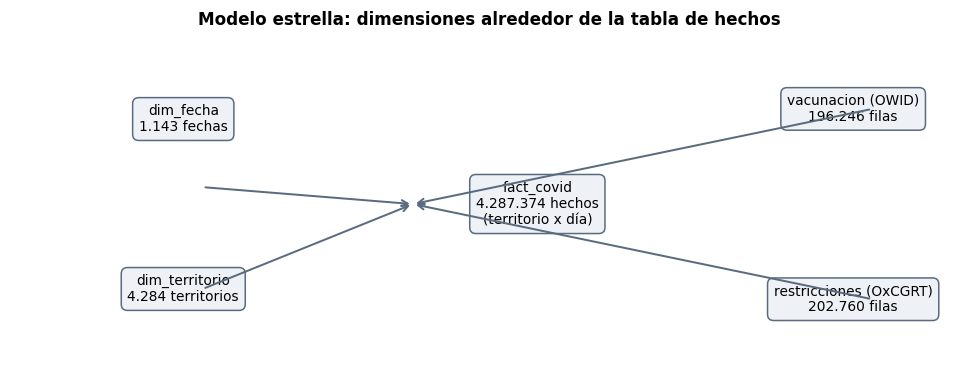

In [13]:
# --- Hito 2 · Esquema en estrella (esquema visual) -------------------------
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axis("off")
cajas = {
    "dim_fecha\n1.143 fechas": (0.18, 0.75),
    "dim_territorio\n4.284 territorios": (0.18, 0.25),
    "fact_covid\n4.287.374 hechos\n(territorio x día)": (0.55, 0.50),
    "vacunacion (OWID)\n196.246 filas": (0.88, 0.78),
    "restricciones (OxCGRT)\n202.760 filas": (0.88, 0.22),
}
for texto, (x, y) in cajas.items():
    ax.text(x, y, texto, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="#eef2f7", edgecolor="#5b6b7f"))
for origen, destino in [(0.18, 0.55), (0.18, 0.25), (0.88, 0.78), (0.88, 0.22)]:
    ax.annotate("", xy=(0.42, 0.50), xytext=(origen + 0.02, destino),
                arrowprops=dict(arrowstyle="->", color="#5b6b7f", lw=1.3))
ax.set_title("Modelo estrella: dimensiones alrededor de la tabla de hechos", fontsize=11, weight="bold")
fig.tight_layout()
plt.show()

### Hito 2 · 2.4 Calidad y gobernanza (R2)

La calidad **no** se corrige a ojo: se mide con reglas ejecutables en seis dimensiones (completitud, unicidad, validez, consistencia, exactitud y oportunidad). Cada regla tiene **umbral, valor medido, estado y decisión**; ninguna revisión de la fuente se borra: se **marca**.

In [14]:
# --- Hito 2 · Reglas de calidad ejecutables --------------------------------
from calidad import mediciones, reglas, indice_pais

med = mediciones(con)
tabla_reglas = pd.DataFrame(reglas(med)).rename(columns={
    "dimension": "Dimensión", "nombre": "Regla", "umbral": "Umbral",
    "valor": "Valor medido", "estado": "Estado", "decision": "Decisión"})
tabla_reglas["Estado"] = tabla_reglas["Estado"].map(
    {"ok": "Correcto", "warn": "Advertencia", "fail": "Falla"})
display(tabla_reglas[["Dimensión", "Regla", "Umbral", "Valor medido", "Estado", "Decisión"]]
        .style.set_caption("Reglas de calidad: 5 correctas · 10 advertencias · 1 falla"))

resumen = tabla_reglas["Estado"].value_counts().rename_axis("Estado").reset_index(name="Reglas")
display(resumen)

,Dimensión,Regla,Umbral,Valor medido,Estado,Decisión
0,completitud,cobertura_fechas,1.143/1.143 días con al menos un reporte,1143/1143,Correcto,"Ningún día sin reporte; si apareciera uno, se marcaría y se documentaría."
1,completitud,nulos_confirmed,0 nulos,28 (0.001 %),Advertencia,Se conservan los nulos; no se imputan. Revisar filas afectadas.
2,completitud,nulos_deaths,0 nulos,433 (0.01 %),Advertencia,Se conservan los nulos; no se imputan.
3,completitud,recovered_active_discontinuados,informativa: JHU dejó de publicarlos (desde 2021-03),recovered nulos 65.971 %; active nulos 66.189 %,Advertencia,No se usan como serie completa; se excluyen de P1–P7 y de modelos.
4,completitud,poblacion_territorios,>= 90 % de territorios con población,4019/4284 con población,Correcto,Los sin población (barcos/eventos y algunos territorios) no entran en tasas por 100.000.
5,unicidad,duplicados_territorio_fecha,0 tras consolidación (se conserva la fila de mayor acumulado),0,Correcto,99 pares mismo territorio/fecha (grafo de transición de nombres) fusionados conservando el max.
6,validez,acumulados_negativos,0 filas con confirmed/deaths/recovered < 0,7 filas,Falla,Errores del origen (correcciones publicadas como filas). Se conservan y se MARCAN; se excluyen de promedios y modelos; no se usan para diferenciar nuevos.
7,validez,lat_long_rango,"lat en [-90,90], long en [-180,180]",0 lat; 0 long,Correcto,Sin violaciones.
8,validez,poblacion_positiva,población > 0 cuando existe,0 violaciones,Correcto,Sin violaciones.
9,validez,cfr_sobre_100,0 (o explicar); aquí: valores extremos por bajas en testeo o correcciones,2001 filas,Advertencia,Se conservan; no se usan para comparar letalidad entre países sin advertencia.


,Estado,Reglas
0,Advertencia,10
1,Correcto,5
2,Falla,1


,País (ISO3),Índice de calidad,Retrocesos,Días con vacío > 7 d,Fallecidos > casos,Acumulados negativos,Letalidad > 100 %
0,USA,34.000000,54746,0,7125,3,1347
89,COL,64.100000,234,1,508,4,3
209,PER,65.800000,466,0,13,0,3
21,BEL,69.500000,18,0,348,0,348
61,PRK,70.000000,0,0,300,0,299
106,NLD,71.400000,300,0,64,0,1
52,CAN,78.700000,51,0,1039,0,0
148,GBR,79.300000,26,0,1377,0,0
78,DEU,88.000000,454,0,0,0,0
65,MEX,89.400000,390,1,0,0,0


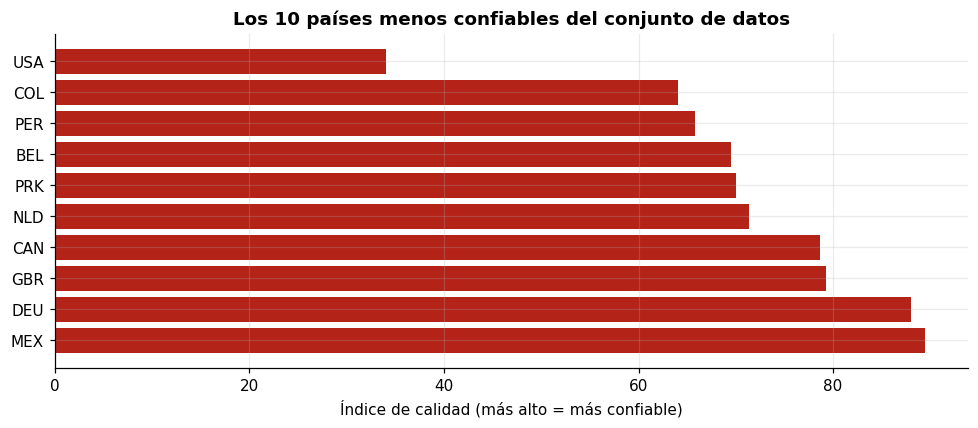

In [15]:
# --- Hito 2 · Índice de confiabilidad por país ------------------------------
idx = indice_pais(con).copy()
peores = (idx.nsmallest(10, "indice")
          .loc[:, ["pais_iso3", "indice", "retrocesos", "gaps_largos", "deaths_gt_confirmed",
                   "negativas", "cfr_100"]]
          .rename(columns={"pais_iso3": "País (ISO3)", "indice": "Índice de calidad",
                            "retrocesos": "Retrocesos", "gaps_largos": "Días con vacío > 7 d",
                            "deaths_gt_confirmed": "Fallecidos > casos",
                            "negativas": "Acumulados negativos", "cfr_100": "Letalidad > 100 %"}))
display(peores.style.set_caption("Los 10 países con peor índice de calidad (100 = sin problemas)"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(peores["País (ISO3)"], peores["Índice de calidad"], color="#b42318")
ax.set_xlabel("Índice de calidad (más alto = más confiable)")
ax.set_title("Los 10 países menos confiables del conjunto de datos", weight="bold")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

### Hito 2 · 2.5 Fuentes externas (OWID y OxCGRT)

Las dos fuentes externas se cruzan con JHU por **código ISO3**. Lo importante no es solo el porcentaje que cruza, sino **declarar los límites**: qué países no cruzan, por qué y qué se hace con ellos.

In [16]:
# --- Hito 2 · Cobertura de las fuentes externas -----------------------------
from analisis_restricciones import cobertura

restaurar_backend_interactivo()

cov = cobertura(con)
paises_jhu = cov["jhu_total"]

owid_paises = con.execute("""
    SELECT count(DISTINCT v.pais_iso3) FROM v_nacional_acum v
    WHERE v.pais_iso3 IN (
        SELECT DISTINCT iso3 FROM vacunacion
        WHERE iso3 IS NOT NULL AND NOT es_agregado)
""").fetchone()[0]
print(f"OWID (vacunación): {owid_paises} países de JHU con datos de vacunación")
print(f"OxCGRT (restricciones): {cov['paises']} países de origen, {cov['filas']:,} filas país-día, "
      f"del {cov['fmin'].date()} al {cov['fmax'].date()}")
print(f"OxCGRT cruza con {cov['cruz']}/{paises_jhu} países de JHU ({100 * cov['cruz'] / paises_jhu:.1f} %)")

cobertura_tabla = pd.DataFrame([
    {"Fuente externa": "Our World in Data (vacunación)", "Filas": "196.246",
     "Cruzan con JHU": f"{owid_paises}/{paises_jhu}",
     "Cobertura": f"{100 * owid_paises / paises_jhu:.1f} %",
     "Uso en el proyecto": "Pregunta P7 (vacunación vs mortalidad)"},
    {"Fuente externa": "Oxford OxCGRT (restricciones)", "Filas": f"{cov['filas']:,}",
     "Cruzan con JHU": f"{cov['cruz']}/{paises_jhu}",
     "Cobertura": f"{100 * cov['cruz'] / paises_jhu:.1f} %",
     "Uso en el proyecto": "Análisis extra: respuesta política frente a las olas"},
])
display(cobertura_tabla.style.set_caption("Cobertura de las fuentes externas (cruce por ISO3)"))
print("Países de JHU sin OxCGRT (muestra):", ", ".join(cov["jhu_sin"][:12]), "…")
print("Países de OxCGRT sin equivalente en JHU:", ", ".join(cov["sin_cruce"]))

OWID (vacunación): 201 países de JHU con datos de vacunación
OxCGRT (restricciones): 185 países de origen, 202,760 filas país-día, del 2020-01-01 al 2022-12-31
OxCGRT cruza con 182/218 países de JHU (83.5 %)


,Fuente externa,Filas,Cruzan con JHU,Cobertura,Uso en el proyecto
0,Our World in Data (vacunación),196.246,201/218,92.2 %,Pregunta P7 (vacunación vs mortalidad)
1,Oxford OxCGRT (restricciones),"202,760",182/218,83.5 %,Análisis extra: respuesta política frente a las olas


Países de JHU sin OxCGRT (muestra): ARM, ATA, ATG, BLM, COK, COM, CUW, CYM, FSM, GGY, GIB, GLP …
Países de OxCGRT sin equivalente en JHU: BMU, TKM, VIR


### Hito 2 · 2.6 Consultas OLAP sobre el almacén

Las preguntas del enunciado se resuelven **contra el DW** (roll-up, drill-down, slice y dice), nocontra los CSV sueltos. Estas son las cuatro operaciones, con el grano y la lógica a la vista.

In [17]:
# --- Hito 2 · Consultas OLAP de verificación --------------------------------
# ROLL-UP: del territorio al mundo, agregando por año.
rollup = con.execute("""
    SELECT d.anio AS "Año",
           sum(v.new_confirmed) AS "Nuevos casos",
           sum(v.new_deaths) AS "Nuevos fallecidos"
    FROM v_nacional_dia v JOIN dim_fecha d USING (fecha)
    WHERE v.pais_iso3 IS NOT NULL
    GROUP BY 1 ORDER BY 1
""").df()
display(rollup.style.set_caption("ROLL-UP — mundo por año (casos y fallecidos nuevos)"))

,Año,Nuevos casos,Nuevos fallecidos
0,2020,83762020.000000,1901692.000000
1,2021,204911743.000000,3566231.000000
2,2022,371621872.000000,1224558.000000
3,2023,16105439.000000,188428.000000


In [18]:
# DRILL-DOWN: de Chile nacional a cada región, en un año.
drill = con.execute("""
    SELECT region AS "Región",
           sum(new_confirmed) AS "Nuevos casos",
           sum(new_deaths) AS "Nuevos fallecidos",
           round(1e5 * sum(new_confirmed) / max(population), 1) AS "Casos por 100.000",
           round(1e5 * sum(new_deaths) / max(population), 1) AS "Fallecidos por 100.000"
    FROM vl_chile_regiones
    WHERE fecha >= DATE '2021-01-01' AND fecha < DATE '2022-01-01'
    GROUP BY 1 ORDER BY 5 DESC NULLS LAST
""").df()
display(drill.head(8).style.set_caption("DRILL-DOWN — Chile 2021 por región (ordenado por mortalidad)"))

,Región,Nuevos casos,Nuevos fallecidos,Casos por 100.000,Fallecidos por 100.000
0,"Magallanes, Chile",13324.000000,275.000000,8000.800000,165.100000
1,"Tarapaca, Chile",29432.000000,545.000000,8903.700000,164.900000
2,"Los Rios, Chile",44987.000000,634.000000,11689.900000,164.700000
3,"Los Lagos, Chile",73566.000000,1247.000000,8877.200000,150.500000
4,"Arica y Parinacota, Chile",18161.000000,321.000000,8033.400000,142.000000
5,"Biobio, Chile",120371.000000,2045.000000,7731.900000,131.400000
6,"Valparaiso, Chile",102541.000000,2380.000000,5646.800000,131.100000
7,"Araucania, Chile",81222.000000,1254.000000,8485.200000,131.000000


In [19]:
# SLICE y DICE: un año y cuatro países, con y sin filtro de fecha.
dice = con.execute("""
    SELECT v.pais_iso3 AS "País (ISO3)",
           sum(v.new_confirmed) AS "Nuevos casos (2021)",
           sum(v.new_deaths) AS "Nuevos fallecidos (2021)",
           round(1e5 * max(v.confirmed) / max(v.poblacion), 1) AS "Acumulados por 100.000"
    FROM v_nacional_dia v
    WHERE v.pais_iso3 IN ('CHL', 'PER', 'USA', 'BRA')
      AND v.fecha >= DATE '2021-01-01' AND v.fecha < DATE '2022-01-01'
    GROUP BY 1 ORDER BY 2 DESC
""").df()
display(dice.style.set_caption("DICE — Chile, Perú, EE.UU. y Brasil, año 2021"))

,País (ISO3),Nuevos casos (2021),Nuevos fallecidos (2021),Acumulados por 100.000
0,USA,34675558.000000,474715.000000,16659.700000
1,BRA,14610807.000000,424262.000000,10487.300000
2,PER,1281694.000000,109620.000000,6966.000000
3,CHL,1197521.000000,22507.000000,9450.100000


---

# HITO 3 · Análisis, modelos, alertas y tablero (hasta 18-nov)

**Qué se hizo:** responder P1–P6 con **número, gráfico e interpretación**, resolver la pregunta P7 con una fuente externa, segmentar países, pronosticar sin fuga de datos, evaluar la alerta temprana en la historia de Chile y cerrar con un tablero con «Desafío en vivo».

**Por qué importa:** es el hito que se **defiende**. Cada cifra debe poder responderse con el tablero y con el código, sin depender de la memoria.

**Con qué evidencia:** las celdas siguientes consultan el DW y llaman a los modelos reales (`src/modelos.py`, `src/p7_vacunacion.py`).

### Hito 3 · 3.1 P1 — Chile frente a Sudamérica

Pregunta: **¿dónde está Chile en Sudamérica en casos y mortalidad acumulada por 100.000 habitantes?** Se usan tasas por 100.000 (con la población de referencia de JHU), no cifras absolutas: Chile tiene menos habitantes que Brasil, pero no por eso puede compararse en bruto.

In [20]:
# --- Hito 3 · P1 · Chile vs Sudamérica (tasas por 100.000) --------------------
NOMBRES_SA = {"CHL": "Chile", "ARG": "Argentina", "PER": "Perú", "COL": "Colombia",
              "BRA": "Brasil", "ECU": "Ecuador", "URY": "Uruguay", "PRY": "Paraguay",
              "BOL": "Bolivia", "VEN": "Venezuela"}

sa = con.execute("""
    SELECT pais_iso3, max(confirmed) AS casos, max(deaths) AS fallecidos, max(poblacion) AS poblacion
    FROM v_nacional_acum
    WHERE pais_iso3 IN ('CHL','ARG','PER','COL','BRA','ECU','URY','PRY','BOL','VEN')
    GROUP BY 1
""").df()
sa["País"] = sa["pais_iso3"].map(NOMBRES_SA)
sa["Casos por 100.000"] = (1e5 * sa["casos"] / sa["poblacion"]).round(0)
sa["Fallecidos por 100.000"] = (1e5 * sa["fallecidos"] / sa["poblacion"]).round(1)
p1 = sa.sort_values("Casos por 100.000", ascending=False)[
    ["País", "Casos por 100.000", "Fallecidos por 100.000"]].reset_index(drop=True)
p1.index += 1
p1.index.name = "Posición"
display(p1.style.set_caption("P1 — Sudamérica, acumulados por 100.000 habitantes (cierre 9-mar-2023)"))

,País,Casos por 100.000,Fallecidos por 100.000
Posición,,,
1,Uruguay,29775.000000,219.300000
2,Chile,27162.000000,336.200000
3,Argentina,22225.000000,288.700000
4,Brasil,17445.000000,329.000000
5,Perú,13610.000000,665.800000
6,Colombia,12498.000000,279.700000
7,Paraguay,11334.000000,278.700000
8,Bolivia,10231.000000,191.600000
9,Ecuador,5992.000000,204.100000


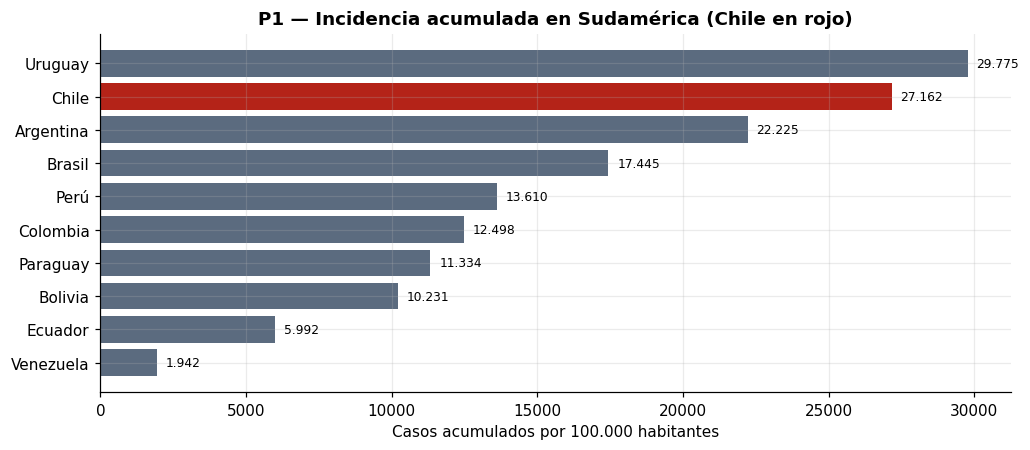

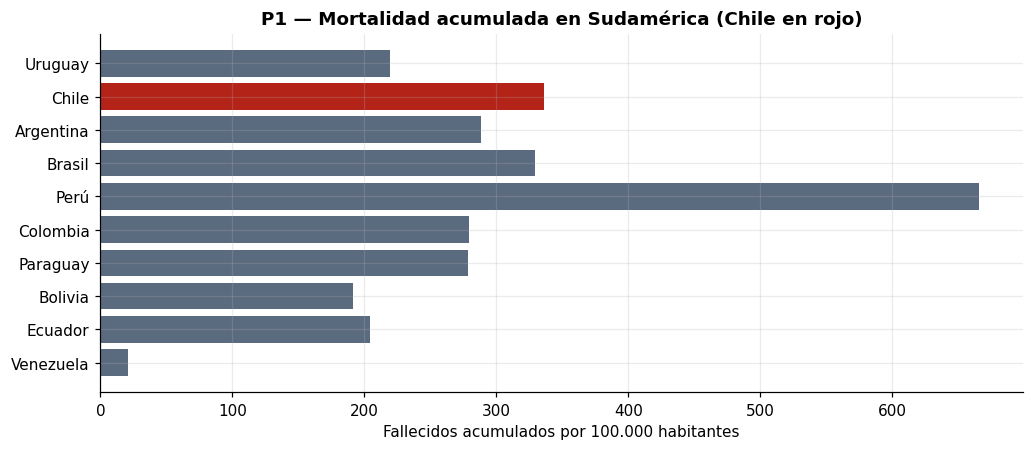

Lectura: Chile es 2.º en incidencia (27.162 casos/100.000) y 2.º en mortalidad aparente (336,2/100.000), detrás de Perú (665,8/100.000), cuya cifra está inflada por la reconciliación de 2021.


In [21]:
# --- Hito 3 · P1 · gráfico y lectura ---------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 4.2))
colores = ["#b42318" if p == "Chile" else "#5b6b7f" for p in p1["País"]]
ax.barh(p1["País"], p1["Casos por 100.000"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("Casos acumulados por 100.000 habitantes")
ax.set_title("P1 — Incidencia acumulada en Sudamérica (Chile en rojo)", weight="bold")
for y, v in enumerate(p1["Casos por 100.000"]):
    ax.text(v + 300, y, f"{v:,.0f}".replace(",", "."), va="center", fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.barh(p1["País"], p1["Fallecidos por 100.000"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("Fallecidos acumulados por 100.000 habitantes")
ax.set_title("P1 — Mortalidad acumulada en Sudamérica (Chile en rojo)", weight="bold")
fig.tight_layout()
plt.show()
print("Lectura: Chile es 2.º en incidencia (27.162 casos/100.000) y 2.º en mortalidad aparente "
      "(336,2/100.000), detrás de Perú (665,8/100.000), cuya cifra está inflada por la reconciliación de 2021.")

### Hito 3 · 3.2 P2 — Regiones de Chile (desde junio de 2020)

Desde el 20-may-2020 Chile se reporta **por regiones**, así que el análisis territorial solo es válido a partir de esa fecha. `Unknown, Chile` se reporta aparte y **no entra** en los rankings.

,Posición,Región,Nuevos casos,Nuevos fallecidos,Casos por 100.000,Fallecidos por 100.000
0,1,"Magallanes, Chile",66597.000000,755.000000,39990.000000,453.400000
1,2,"Metropolitana, Chile",1886885.000000,30094.000000,26528.000000,423.100000
2,3,"Arica y Parinacota, Chile",79099.000000,893.000000,34989.000000,395.000000
3,4,"Los Rios, Chile",147896.000000,1405.000000,38431.000000,365.100000
4,5,"Valparaiso, Chile",489750.000000,6395.000000,26970.000000,352.200000
5,6,"Tarapaca, Chile",111181.000000,1152.000000,33634.000000,348.500000
6,7,"Maule, Chile",345507.000000,3339.000000,33064.000000,319.500000
7,8,"Antofagasta, Chile",181301.000000,1930.000000,29842.000000,317.700000
8,9,"Los Lagos, Chile",242197.000000,2564.000000,29226.000000,309.400000
9,10,"Biobio, Chile",508751.000000,4813.000000,32679.000000,309.200000


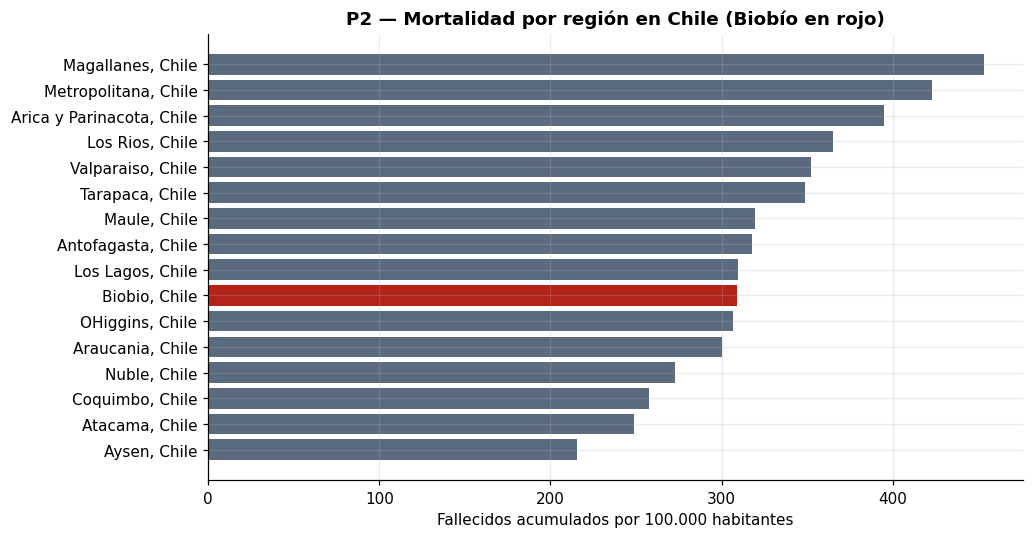

Lectura: Biobío ocupa el puesto 10 de 16 en mortalidad aparente, en línea con su incidencia; Magallanes y Metropolitana lideran el ranking.


In [22]:
# --- Hito 3 · P2 · Regiones de Chile por mortalidad -------------------------
regiones = con.execute("""
    SELECT region AS "Región",
           sum(new_confirmed) AS "Nuevos casos",
           sum(new_deaths) AS "Nuevos fallecidos",
           round(1e5 * sum(new_confirmed) / max(population), 0) AS "Casos por 100.000",
           round(1e5 * sum(new_deaths) / max(population), 1) AS "Fallecidos por 100.000"
    FROM vl_chile_regiones
    WHERE fecha >= DATE '2020-06-01' AND region <> 'Unknown, Chile'
    GROUP BY 1 ORDER BY 5 DESC
""").df()
regiones.insert(0, "Posición", range(1, len(regiones) + 1))
display(regiones.style.set_caption("P2 — Regiones de Chile desde junio de 2020 (ordenado por mortalidad)"))

fig, ax = plt.subplots(figsize=(9.5, 5))
colores = ["#b42318" if r == "Biobio, Chile" else "#5b6b7f" for r in regiones["Región"]]
ax.barh(regiones["Región"], regiones["Fallecidos por 100.000"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("Fallecidos acumulados por 100.000 habitantes")
ax.set_title("P2 — Mortalidad por región en Chile (Biobío en rojo)", weight="bold")
fig.tight_layout()
plt.show()
print("Lectura: Biobío ocupa el puesto 10 de 16 en mortalidad aparente, en línea con su incidencia; "
      "Magallanes y Metropolitana lideran el ranking.")

### Hito 3 · 3.3 P3 — Letalidad aparente antes y después de la vacunación

La **letalidad aparente** (fallecidos/casos) cayó con la vacunación, pero parte de esa caída es **mecánica**: con ómicron se detectaron muchos más casos leves. Por eso la comparación se apoya en **fallecidos por 100.000** y no solo en la razón.

,Período,Letalidad aparente (%)
0,Acumulado hasta enero de 2021 (pre-vacunación),2.540000
1,Desde junio de 2021 (vacunación masiva),0.920000


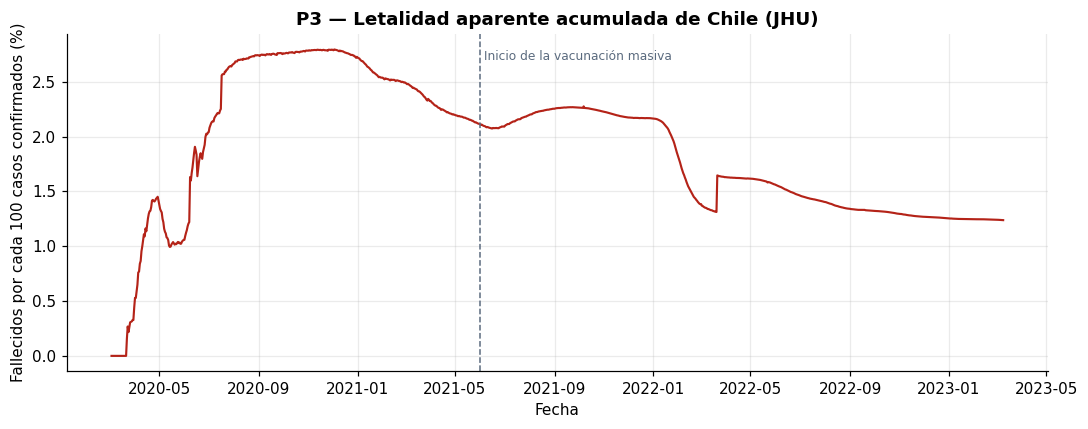

Lectura: la letalidad aparente cae de 2,54 % a 0,92 %; parte de esa mejora es efecto de testeo, no solo de vacunación.


In [23]:
# --- Hito 3 · P3 · Letalidad aparente de Chile ------------------------------
chl = con.execute("""
    SELECT fecha, confirmed, deaths FROM v_nacional_acum
    WHERE pais_iso3 = 'CHL' ORDER BY fecha
""").df()
chl["fecha"] = pd.to_datetime(chl["fecha"])

pre = chl[chl["fecha"] <= pd.Timestamp("2021-01-31")].iloc[-1]
post = chl[chl["fecha"] >= pd.Timestamp("2021-06-01")]
cfr_pre = 100 * pre["deaths"] / pre["confirmed"]
cfr_post = 100 * (post["deaths"].iloc[-1] - post["deaths"].iloc[0]) / (post["confirmed"].iloc[-1] - post["confirmed"].iloc[0])

p3 = pd.DataFrame([
    {"Período": "Acumulado hasta enero de 2021 (pre-vacunación)",
     "Letalidad aparente (%)": round(cfr_pre, 2)},
    {"Período": "Desde junio de 2021 (vacunación masiva)",
     "Letalidad aparente (%)": round(cfr_post, 2)},
])
display(p3.style.set_caption("P3 — Letalidad aparente de Chile"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(chl["fecha"], 100 * chl["deaths"] / chl["confirmed"], color="#b42318", linewidth=1.4)
ax.axvline(pd.Timestamp("2021-06-01"), color="#5b6b7f", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2021-06-01"), ax.get_ylim()[1] * 0.92, " Inicio de la vacunación masiva",
        fontsize=8, color="#5b6b7f")
ax.set_title("P3 — Letalidad aparente acumulada de Chile (JHU)", weight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Fallecidos por cada 100 casos confirmados (%)")
fig.tight_layout()
plt.show()
print("Lectura: la letalidad aparente cae de 2,54 % a 0,92 %; parte de esa mejora es efecto de testeo, "
      "no solo de vacunación.")

### Hito 3 · 3.4 P4 — ¿En qué países se puede uno fiar?

La pregunta no es solo cuánto virus hubo, sino **cuánto se puede confiar en el dato de cada país**. El índice de calidad combina retrocesos, vacíos largos, fallecidos > casos, negativos y letalidad > 100 %.

In [24]:
# --- Hito 3 · P4 · Confiabilidad por país -----------------------------------
p4 = (idx.nsmallest(10, "indice")
      .loc[:, ["pais_iso3", "indice", "retrocesos", "gaps_largos", "deaths_gt_confirmed",
               "negativas", "cfr_100"]]
      .rename(columns={"pais_iso3": "País (ISO3)", "indice": "Índice de calidad",
                        "retrocesos": "Retrocesos", "gaps_largos": "Días con vacío > 7 d",
                        "deaths_gt_confirmed": "Fallecidos > casos",
                        "negativas": "Acumulados negativos", "cfr_100": "Letalidad > 100 %"}))
display(p4.style.set_caption("P4 — Los 10 países con peor índice de calidad"))
print("Decisiones: (1) los retrocesos se conservan y se marcan, nunca se borran; "
      "(2) los días de corrección masiva (2022-05-23) se excluyen de promedios y modelos; "
      "(3) las filas negativas crudas se excluyen del análisis; "
      "(4) para rankings solo se usan países con población conocida.")

,País (ISO3),Índice de calidad,Retrocesos,Días con vacío > 7 d,Fallecidos > casos,Acumulados negativos,Letalidad > 100 %
0,USA,34.000000,54746,0,7125,3,1347
89,COL,64.100000,234,1,508,4,3
209,PER,65.800000,466,0,13,0,3
21,BEL,69.500000,18,0,348,0,348
61,PRK,70.000000,0,0,300,0,299
106,NLD,71.400000,300,0,64,0,1
52,CAN,78.700000,51,0,1039,0,0
148,GBR,79.300000,26,0,1377,0,0
78,DEU,88.000000,454,0,0,0,0
65,MEX,89.400000,390,1,0,0,0


Decisiones: (1) los retrocesos se conservan y se marcan, nunca se borran; (2) los días de corrección masiva (2022-05-23) se excluyen de promedios y modelos; (3) las filas negativas crudas se excluyen del análisis; (4) para rankings solo se usan países con población conocida.


### Hito 3 · 3.5 P5 — Segmentación de paísespandemias parecidas

La forma pura de la curva (incidencia semanal normalizada) resultó **homogénea en todo el mundo** (silueta 0,09: todos los picos convergen en ómicron), así que se segmentó por **indicadores**: log de casos y fallecidos por 100.000, log de la letalidad aparente, cuota de casos en 2020 y en 2022+, y número de olas. El grupo se elige por **silueta** (k = 3, silueta 0,325).

> El gráfico lo produce `src/analisis_p1_p6.py` (segmentación sobre 131 países con ≥ 100.000 casos); aquí se muestra el resultado y se citan sus cifras.

,Grupo,Países,Casos/100k medio,Fallecidos/100k medio,Letalidad aparente (%),Cuota de casos en 2022 (%),Muestra
0,0,54,15236,231.200000,1.500000,37,"Albania, Emiratos, Argentina, Armenia, Azerbaiyán"
1,1,26,1248,19.200000,1.410000,22,"Afganistán, Angola, Bangladesh, China, Camerún"
2,2,51,39520,164.800000,0.410000,68,"Australia, Austria, Bélgica, Bahréin, Barbados"


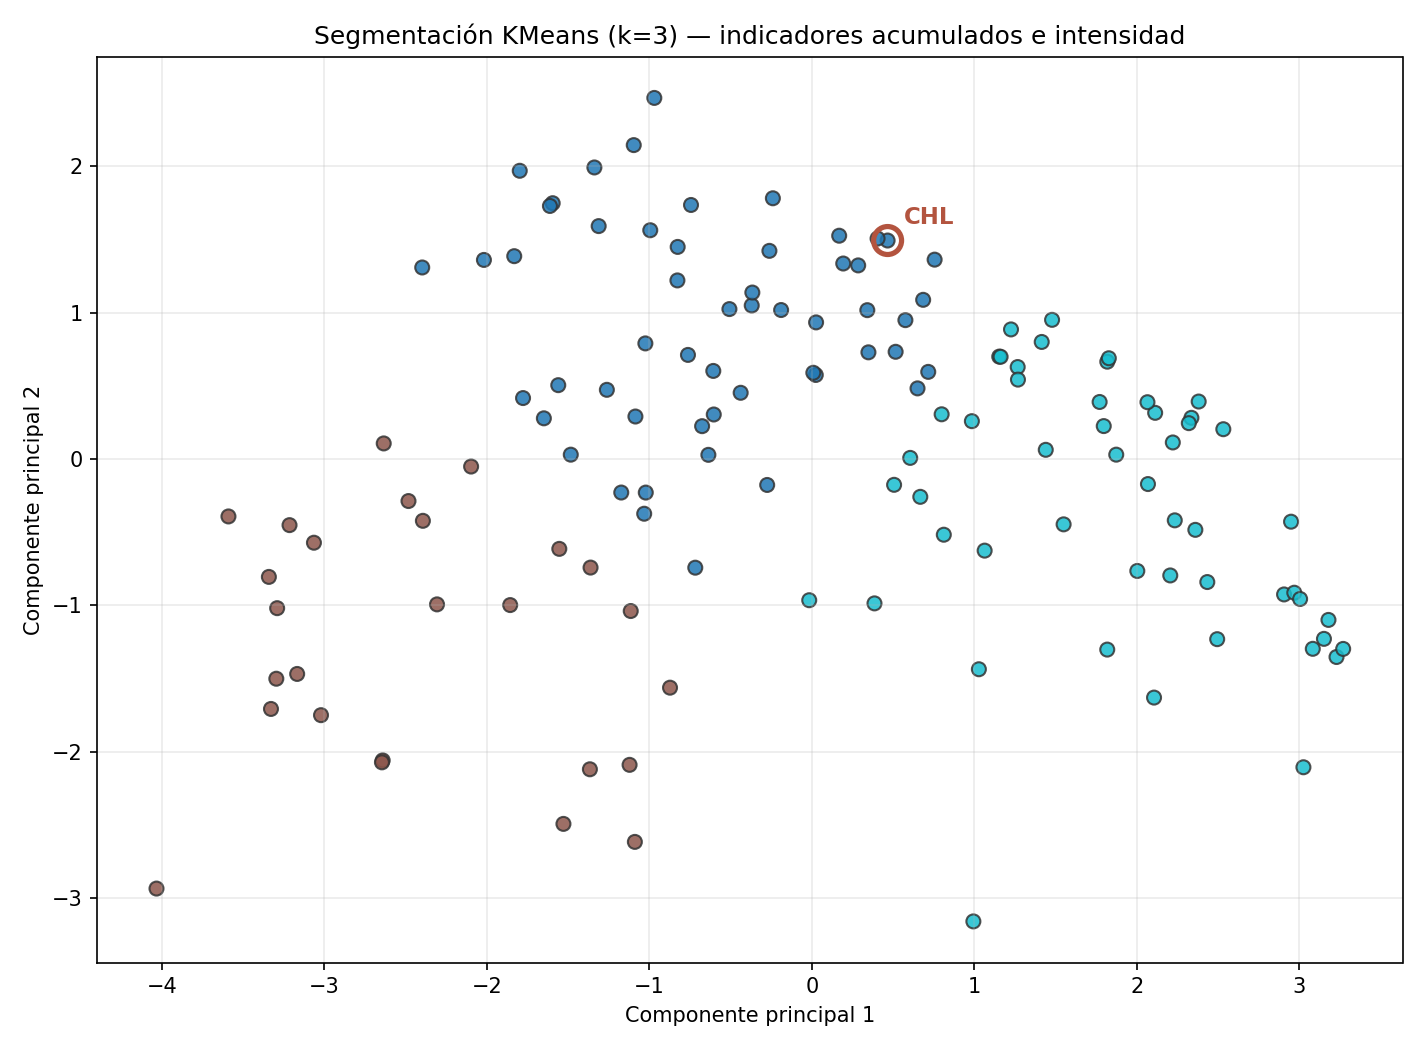

Chile queda en el grupo 0 (América Latina + Europa del Este + EE.UU.): pandemias de olas múltiples con letalidad aparente alta (~1–2 %), donde el esfuerzo de 2020–2021 quedó eclipsado por ómicron en volumen.


In [25]:
# --- Hito 3 · P5 · Grupos de países con pandemias parecidas -----------------
p5 = pd.DataFrame([
    {"Grupo": 0, "Países": 54, "Casos/100k medio": 15236, "Fallecidos/100k medio": 231.2,
     "Letalidad aparente (%)": 1.50, "Cuota de casos en 2022 (%)": 37,
     "Muestra": "Albania, Emiratos, Argentina, Armenia, Azerbaiyán"},
    {"Grupo": 1, "Países": 26, "Casos/100k medio": 1248, "Fallecidos/100k medio": 19.2,
     "Letalidad aparente (%)": 1.41, "Cuota de casos en 2022 (%)": 22,
     "Muestra": "Afganistán, Angola, Bangladesh, China, Camerún"},
    {"Grupo": 2, "Países": 51, "Casos/100k medio": 39520, "Fallecidos/100k medio": 164.8,
     "Letalidad aparente (%)": 0.41, "Cuota de casos en 2022 (%)": 68,
     "Muestra": "Australia, Austria, Bélgica, Bahréin, Barbados"},
])
display(p5.style.set_caption("P5 — Segmentación por indicadores (k = 3, silueta 0,325)"))

figura_p5 = REPORTS_DIR / "fig_p5_clusters.png"
if figura_p5.exists():
    display(Image(filename=str(figura_p5), width=900))
print("Chile queda en el grupo 0 (América Latina + Europa del Este + EE.UU.): pandemias de olas múltiples "
      "con letalidad aparente alta (~1–2 %), donde el esfuerzo de 2020–2021 quedó eclipsado por ómicron en volumen.")

### Hito 3 · 3.6 Modelos: pronóstico y backtesting

Dos modelos —**promedio de la MA7** (base) y **Holt** (tendencia amortiguada)— se evalúan en **tres fechas de corte** con horizonte de 14 días. La regla del proyecto: el pronóstico **solo puede usar datos anteriores o iguales a la fecha consultada** (sin fuga de información).

,Fecha de corte,MAE base,MAPE base (%),MAE Holt,MAPE Holt (%)
0,2020-09-15,267.620000,18.850000,262.570000,17.200000
1,2021-03-15,1593.910000,24.730000,1474.940000,23.680000
2,2021-12-01,564.210000,42.290000,451.030000,25.690000


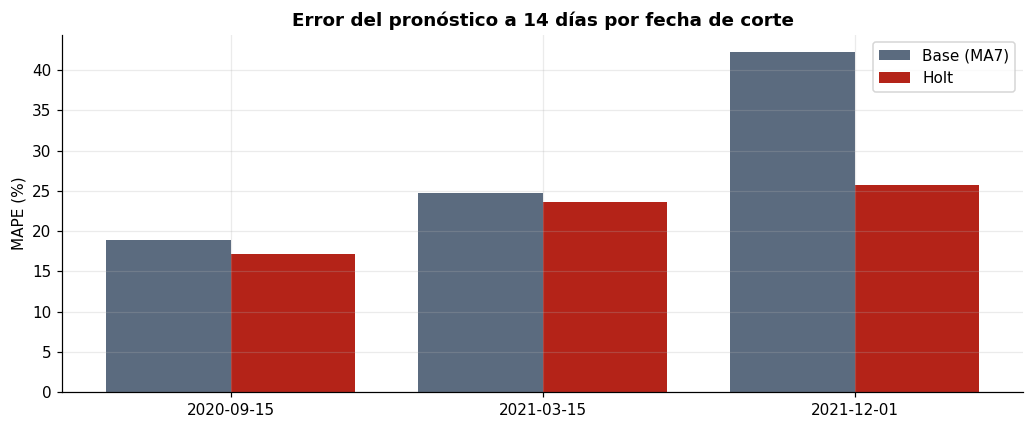

Lectura: Holt mejora el error en los tres cortes. Pero ómicron NO era extrapolable 14 días antes (corte 2021-12-01: la curva era plana). La alerta, en cambio, sí lo anticipó.


In [26]:
# --- Hito 3 · Pronóstico y backtesting (sin fuga de datos) ------------------
from modelos import backtest, pronosticar, alerta, evaluar_alerta, serie_diaria

cortes = ["2020-09-15", "2021-03-15", "2021-12-01"]
bt = backtest("CHL", cortes, horizonte=14).rename(columns={
    "corte": "Fecha de corte", "base_mae": "MAE base", "base_mape": "MAPE base (%)",
    "holt_mae": "MAE Holt", "holt_mape": "MAPE Holt (%)"})
display(bt.style.set_caption("Backtesting en tres cortes (horizonte 14 días)"))

fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(bt))
ax.bar(x - 0.2, bt["MAPE base (%)"], width=0.4, label="Base (MA7)", color="#5b6b7f")
ax.bar(x + 0.2, bt["MAPE Holt (%)"], width=0.4, label="Holt", color="#b42318")
ax.set_xticks(x, bt["Fecha de corte"])
ax.set_ylabel("MAPE (%)")
ax.set_title("Error del pronóstico a 14 días por fecha de corte", weight="bold")
ax.legend()
fig.tight_layout()
plt.show()
print("Lectura: Holt mejora el error en los tres cortes. Pero ómicron NO era extrapolable 14 días antes "
      "(corte 2021-12-01: la curva era plana). La alerta, en cambio, sí lo anticipó.")

In [27]:
# --- Hito 3 · P6 · Alerta temprana evaluada en la historia de Chile ---------
olas = ["2020-06-17", "2021-04-14", "2022-02-13", "2022-06-17", "2022-11-10"]
ev = evaluar_alerta("CHL", olas)

filas_alerta = []
for fecha_ola, info in ev["olas"].items():
    filas_alerta.append({
        "Ola (pico MA7)": fecha_ola,
        "Primera alerta": info["primera_alerta"],
        "Anticipación (días)": info["anticipacion_dias"],
        "Activaciones en la ola": info["activaciones"],
    })
tabla_alerta = pd.DataFrame(filas_alerta)
display(tabla_alerta.style.set_caption("P6 — Alerta temprana: anticipación por ola"))

resumen_alerta = pd.DataFrame([
    {"Indicador": "Activaciones de la alerta en todo el período",
     "Valor": ev["activaciones"]},
    {"Indicador": "Falsas alarmas estrictas",
     "Valor": len(ev["falsas_alarmas"])},
    {"Indicador": "Fechas de falsa alarma", "Valor": ", ".join(ev["falsas_alarmas"]) or "—"},
    {"Indicador": "Alzas menores sin ola mayor",
     "Valor": ", ".join(ev["alzas_menores_sin_ola_mayor"]) or "—"},
    {"Indicador": "Anticipación mediana (días)",
     "Valor": int(np.median(tabla_alerta["Anticipación (días)"]))},
])
display(resumen_alerta.style.set_caption("P6 — Resumen de la evaluación de la alerta"))
print("Criterio de la alerta: variación semanal de la incidencia MA7 ≥ +30 % y incidencia ≥ 6 casos/100.000/día.")
print("Lectura: 5 de 5 olas detectadas (39 a 100 días de anticipación, mediana 48) y una sola falsa alarma estricta.")

,Ola (pico MA7),Primera alerta,Anticipación (días),Activaciones en la ola
0,2020-06-17,2020-05-06,42,2
1,2021-04-14,2021-01-04,100,3
2,2022-02-13,2021-11-11,94,2
3,2022-06-17,2022-05-09,39,3
4,2022-11-10,2022-09-23,48,3


,Indicador,Valor
0,Activaciones de la alerta en todo el período,16
1,Falsas alarmas estrictas,1
2,Fechas de falsa alarma,2020-07-26
3,Alzas menores sin ola mayor,"2021-10-17, 2023-02-25"
4,Anticipación mediana (días),48


Criterio de la alerta: variación semanal de la incidencia MA7 ≥ +30 % y incidencia ≥ 6 casos/100.000/día.
Lectura: 5 de 5 olas detectadas (39 a 100 días de anticipación, mediana 48) y una sola falsa alarma estricta.


### Hito 3 · 3.7 P7 — Vacunación y mortalidad ocho semanas después (OWID × JHU)

La pregunta del Hito 1, ya resuelta: se correlaciona la **cobertura de vacunación** con la **mortalidad reportada en las ocho semanas siguientes**, en Chile, Perú, EE.UU. y Brasil. Es una **asociación ecológica descriptiva**: no permite afirmar causalidad.

In [28]:
# --- Hito 3 · P7 · Vacunación vs mortalidad a 8 semanas --------------------
from p7_vacunacion import analizar_pais

restaurar_backend_interactivo()

NOMBRES_P7 = {"CHL": "Chile", "PER": "Perú", "USA": "EE.UU.", "BRA": "Brasil"}
filas_p7 = []
for iso in ["CHL", "PER", "USA", "BRA"]:
    r = analizar_pais(iso)
    filas_p7.append({
        "País": NOMBRES_P7[iso],
        "Fallecidos/100k/sem antes del 50 % de cobertura":
            r["fallecidos_100k_sem_antes_50pct"],
        "Fallecidos/100k/sem después del 50 % de cobertura":
            r["fallecidos_100k_sem_despues_50pct"],
        "Semanas antes": r["semanas_antes_50pct"],
        "Semanas después": r["semanas_despues_50pct"],
        "Spearman (lag 0)": r["spearman_por_lag"][0][1],
        "Mejor correlación (lag)": max(r["spearman_por_lag"], key=lambda t: abs(t[1]))[0],
    })
p7 = pd.DataFrame(filas_p7)
display(p7.style.set_caption("P7 — Vacunación (OWID) y mortalidad posterior (JHU)"))

,País,Fallecidos/100k/sem antes del 50 % de cobertura,Fallecidos/100k/sem después del 50 % de cobertura,Semanas antes,Semanas después,Spearman (lag 0),Mejor correlación (lag)
0,Chile,2.330000,1.250000,68,90,-0.390000,8
1,Perú,6.840000,0.840000,89,69,-0.713000,8
2,EE.UU.,2.400000,1.810000,76,88,-0.335000,8
3,Brasil,3.120000,0.620000,91,73,-0.493000,8


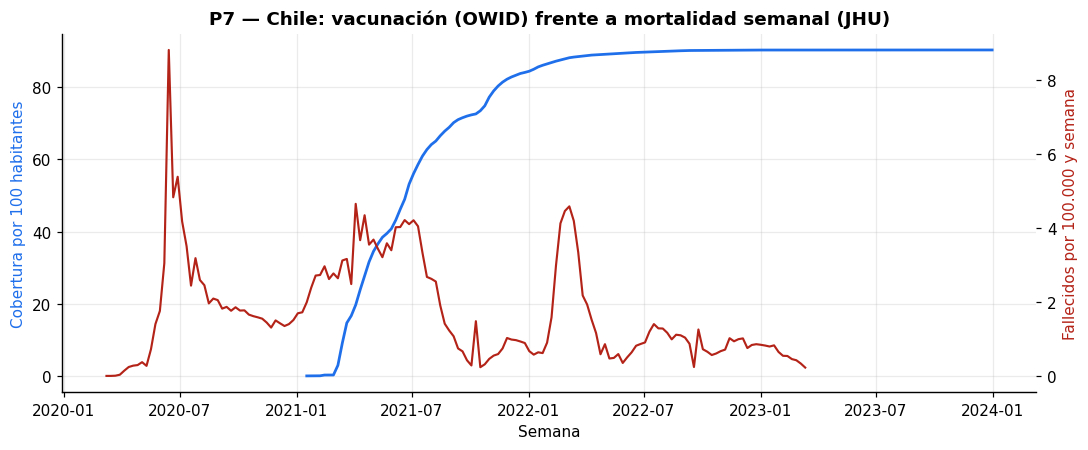

Lectura: la mortalidad semanal cae una vez que la cobertura supera el 50 %; la relación es asociativa y depende del testeo y del calendario sanitario.


In [29]:
# --- Hito 3 · P7 · cobertura de vacunación y mortalidad semanal de Chile ---
from p7_vacunacion import vacunacion_semana, fallecidos_semana

restaurar_backend_interactivo()

vac = vacunacion_semana("CHL")
muerte_sem = fallecidos_semana("CHL")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(vac.index, vac.values, color="#1f6feb", linewidth=1.8, label="Cobertura de vacunación (personas con esquema completo por 100)")
ax.set_ylabel("Cobertura por 100 habitantes", color="#1f6feb")
ax.set_xlabel("Semana")
ax2 = ax.twinx()
ax2.plot(muerte_sem.index, muerte_sem.values, color="#b42318", linewidth=1.4,
         label="Fallecidos por 100.000 y semana")
ax2.set_ylabel("Fallecidos por 100.000 y semana", color="#b42318")
ax2.grid(False)
ax.set_title("P7 — Chile: vacunación (OWID) frente a mortalidad semanal (JHU)", weight="bold")
fig.tight_layout()
plt.show()
print("Lectura: la mortalidad semanal cae una vez que la cobertura supera el 50 %; "
      "la relación es asociativa y depende del testeo y del calendario sanitario.")

### Hito 3 · 3.8 Extra — Restricciones (OxCGRT) frente a las olas

Análisis adicional con la segunda fuente externa: el **índice de respuesta política «de jure»** frente a los casos de JHU en Chile, Perú, EE.UU. y Brasil. También es **descriptivo**: las restricciones se imponen en respuesta a la curva, no al revés (causalidad inversa).

,País,Índice máximo,Fecha del máximo,Media 2020,Media 2021,Media 2022,Días con índice ≥ 70,Primera relajación (2021)
0,Chile,90.280000,2020-07-03,78.456414,64.630603,24.326438,482,2022-01-12
1,Perú,96.300000,2020-05-01,81.886877,63.228740,30.203863,341,2022-07-05
2,EE.UU.,75.460000,2020-11-16,60.590406,56.415452,31.656521,165,2022-04-05
3,Brasil,81.020000,2020-05-05,67.174855,59.724493,28.373068,213,2022-04-21


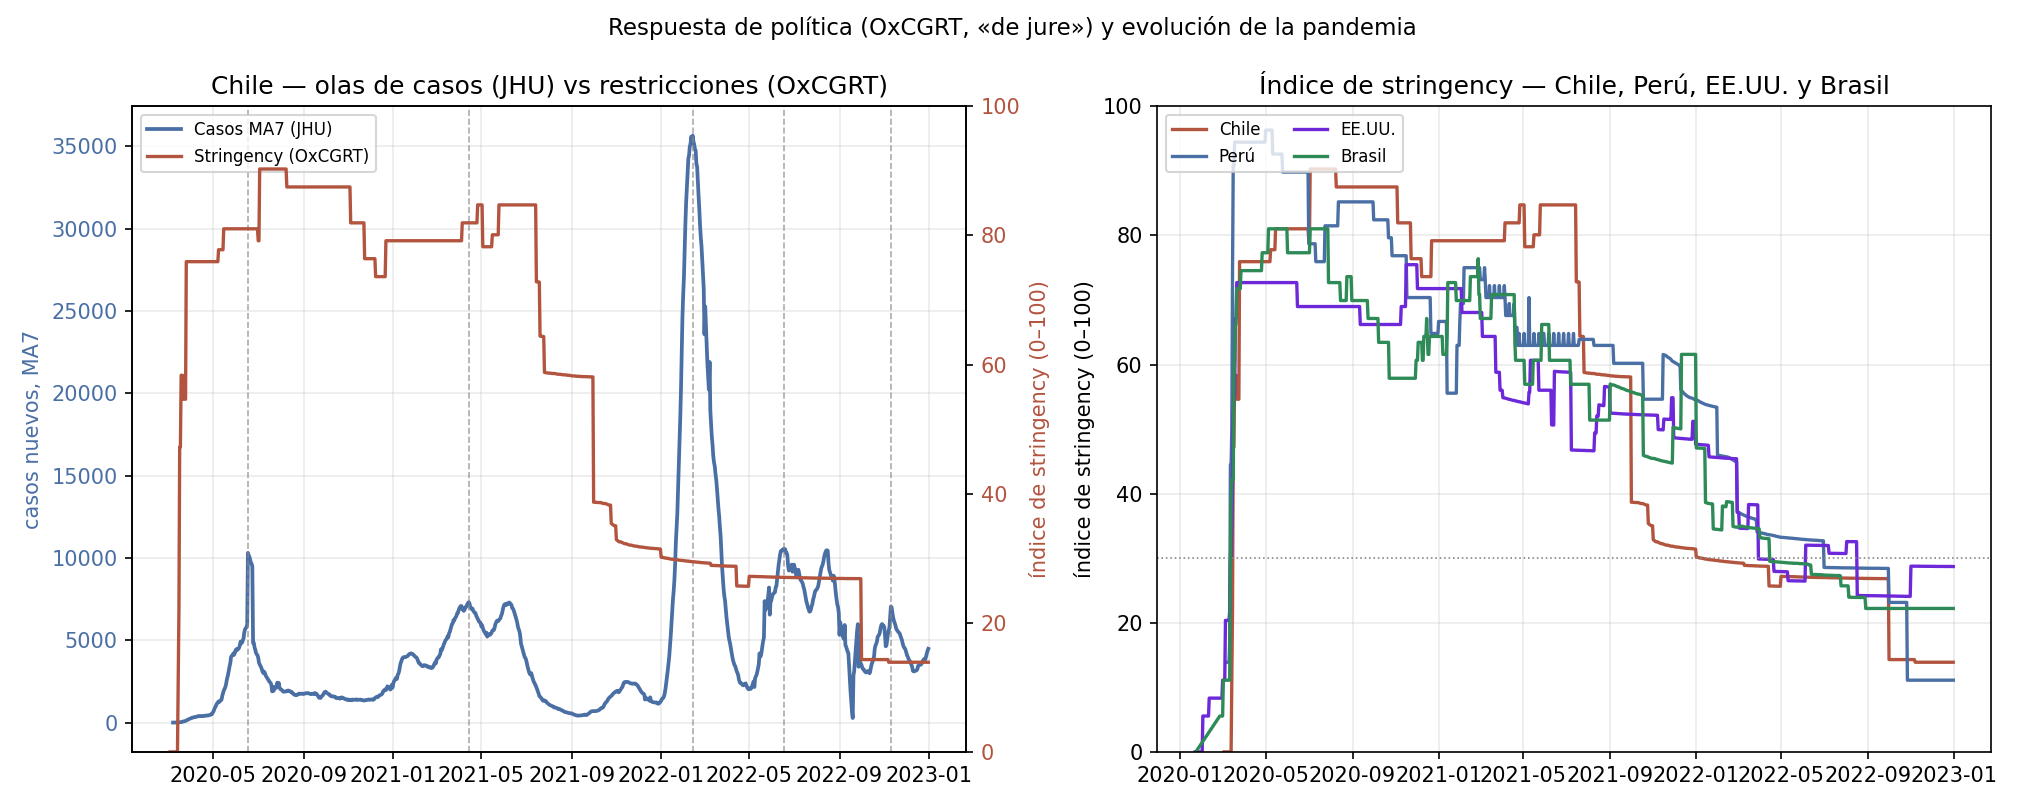

Límites: OxCGRT cierra el 31-dic-2022, 68 días antes que JHU; el análisis es descriptivo, no causal.


In [30]:
# --- Hito 3 · Extra · OxCGRT y olas ----------------------------------------
from analisis_restricciones import serie_pais, resumen

restaurar_backend_interactivo()

filas_rest = []
for iso in ["CHL", "PER", "USA", "BRA"]:
    s = serie_pais(con, iso)
    if s.empty:
        continue
    r = resumen(s["stringency_index"])
    filas_rest.append({
        "País": NOMBRES_P7[iso],
        "Índice máximo": r["max"],
        "Fecha del máximo": r["max_fecha"],
        "Media 2020": r["media_2020"],
        "Media 2021": r["media_2021"],
        "Media 2022": r["media_2022"],
        "Días con índice ≥ 70": r["dias_ge70"],
        "Primera relajación (2021)": r["relajacion"],
    })
restricciones = pd.DataFrame(filas_rest)
display(restricciones.style.set_caption("Extra — Índice de respuesta política (OxCGRT) por país"))

fig_rest = REPORTS_DIR / "fig_restricciones.png"
if fig_rest.exists():
    display(Image(filename=str(fig_rest), width=900))
print("Límites: OxCGRT cierra el 31-dic-2022, 68 días antes que JHU; el análisis es descriptivo, no causal.")

### Hito 3 · 3.9 Tablero y «Desafío en vivo»

El tablero (Streamlit) es la herramienta de la sesión del Comité: KPIs por 100.000, tendencia con media móvil de 7 días, ranking con **supresión de conteos pequeños (<5)**, mapa mundial y regional de Chile, alerta con umbral visible, fecha de corte y advertencias de calidad.

La pestaña **«Desafío en vivo»** sortea un territorio y una fecha, y ejecuta el pronóstico y el estado de la alerta **solo con información disponible hasta esa fecha**. Abajo se replica ese desafío en el notebook.

,Indicador,Valor
0,Territorio,Chile (CHL)
1,Fecha de corte,2021-10-15
2,Alerta activa,No
3,Variación semanal de la incidencia,+35.4%
4,Incidencia MA7 por 100.000,5.360000
5,Umbral de variación,+30%
6,Piso de incidencia,6.0 / 100.000
7,Pronóstico a 14 días (suma de casos diarios),14.350


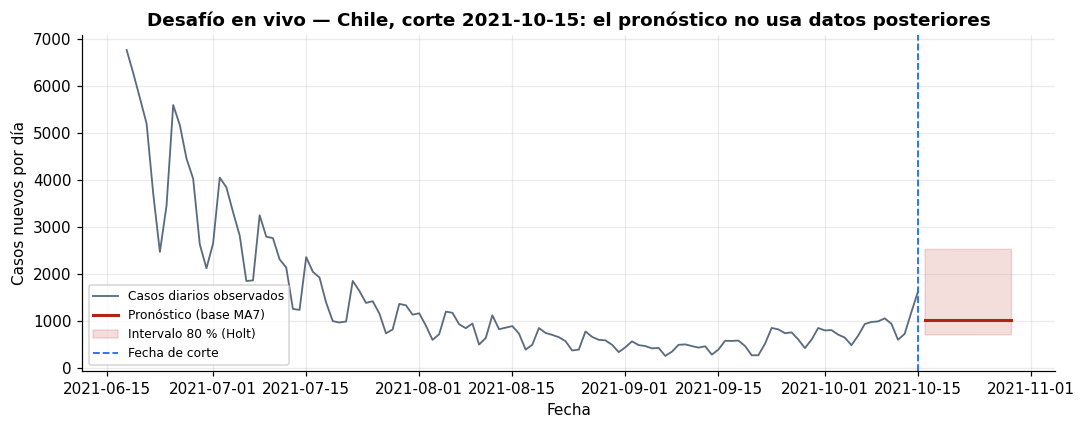

In [31]:
# --- Hito 3 · Desafío en vivo (replicado en el notebook) --------------------
# Fecha de corte del desafío: se puede cambiar por la que sortee el Comité.
fecha_desafio = "2021-10-15"

estado = alerta("CHL", fecha_desafio)
pronostico = pronosticar("CHL", fecha_desafio, horizonte=14)

desafio = pd.DataFrame([
    {"Indicador": "Territorio", "Valor": "Chile (CHL)"},
    {"Indicador": "Fecha de corte", "Valor": fecha_desafio},
    {"Indicador": "Alerta activa", "Valor": "Sí" if estado["activa"] else "No"},
    {"Indicador": "Variación semanal de la incidencia", "Valor": f"{estado['variacion_semanal']:+.1%}"},
    {"Indicador": "Incidencia MA7 por 100.000", "Valor": estado["incidencia_ma7_por_100k"]},
    {"Indicador": "Umbral de variación", "Valor": f"{estado['umbral_variacion']:+.0%}"},
    {"Indicador": "Piso de incidencia", "Valor": f"{estado['piso_incidencia_por_100k']} / 100.000"},
    {"Indicador": "Pronóstico a 14 días (suma de casos diarios)",
     "Valor": f"{pronostico['base_ma7'].sum():,.0f}".replace(",", ".")},
])
display(desafio.style.set_caption("Desafío en vivo — estado de la alerta y pronóstico a 14 días"))

serie = serie_diaria("CHL", hasta=pd.Timestamp(fecha_desafio))
nuevos = serie["confirmed"].diff().clip(lower=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(nuevos.index[-120:], nuevos.values[-120:], color="#5b6b7f", linewidth=1.2, label="Casos diarios observados")
ax.plot(pd.to_datetime(pronostico["fecha"]), pronostico["base_ma7"], color="#b42318", linewidth=2, label="Pronóstico (base MA7)")
ax.fill_between(pd.to_datetime(pronostico["fecha"]), pronostico["limite_inferior"], pronostico["limite_superior"],
                color="#b42318", alpha=0.15, label="Intervalo 80 % (Holt)")
ax.axvline(pd.Timestamp(fecha_desafio), color="#1f6feb", linestyle="--", linewidth=1.2, label="Fecha de corte")
ax.set_title(f"Desafío en vivo — Chile, corte {fecha_desafio}: el pronóstico no usa datos posteriores", weight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Casos nuevos por día")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

---

# Cierre · Estado de los tres hitos

| Hito | Qué se entrega | Evidencia en este notebook | Estado |
|---|---|---|---|
| **1 · Exploración** | Notebook de exploración de ene–jun 2020: inspección, nulos, estandarización, consolidación, top 10, serie de Chile, perfilado, tres observaciones y propuesta P7 | Secciones 1.1 a 1.5 | ✔ Completo |
| **2 · Plataforma** | Descarga automatizada, unificación de 5 esquemas, capa limpia Parquet, reglas de calidad, DW en estrella, OWID y OxCGRT | Secciones 2.1 a 2.6 | ✔ Completo |
| **3 · Análisis y tablero** | P1–P6 con cifras y gráficos, P7 resuelta, segmentación, pronóstico sin fuga de datos, alerta evaluada y tablero con «Desafío en vivo» | Secciones 3.1 a 3.9 | ✔ Completo |

### Qué falta para la entrega final (no pertenece a los hitos)

1. **Nombres del equipo** en `contribuciones.md` y en los informes.
2. **Git/GitHub**: la carpeta todavía **no tiene remoto**; inicializar y subir requiere autorización.
3. **Ensayo con el ayudante (18-nov)**: todos deben poder filtrar el tablero, explicar la alerta y ejecutar el pronóstico a una fecha sorteada.
4. **Sesión del Comité (24-nov)** y **subida del ZIP a EVA (25-nov 23:59)**.

### Documentos relacionados

- `README.md` — cómo reproducir todo desde cero.
- `ROADMAP.md` — avance, hitos y riesgos.
- `docs/diccionario_datos.md` — reglas, decisiones, linaje y cobertura de fuentes.
- `docs/guia_hito_1.md` — guía de lectura rápida del proyecto.
- `docs/informe_tecnico.pdf` (14 pp) y `docs/informe_comite.pdf` (2 pp).

In [32]:
# --- Verificación final: todo lo demostrado quedó consistente --------------
verificaciones = [
    ("Hito 1", "Reportes de ene–jun 2020 consolidados", f"{len(consolidado):,} filas", len(consolidado) > 300000),
    ("Hito 1", "Perfilado automático generado", perfil_path.name, perfil_path.exists()),
    ("Hito 2", "Capas del proyecto disponibles", f"{int((capas['Estado'] == 'Disponible').sum())}/3", (capas["Estado"] == "Disponible").all()),
    ("Hito 2", "Reglas de calidad evaluadas", f"{len(tabla_reglas)} reglas", len(tabla_reglas) >= 15),
    ("Hito 2", "Fuentes externas cruzadas por ISO3", f"OWID {owid_paises}/{paises_jhu} · OxCGRT {cov['cruz']}/{paises_jhu}", True),
    ("Hito 3", "Olas de Chile detectadas por la alerta", f"{len(ev['olas'])}/{len(olas)}", len(ev["olas"]) == len(olas)),
    ("Hito 3", "Backtesting en tres cortes", f"{len(bt)} cortes", len(bt) == 3),
    ("Hito 3", "P7 para los cuatro países", f"{len(p7)} países", len(p7) == 4),
]
resumen_final = pd.DataFrame(verificaciones, columns=["Hito", "Verificación", "Resultado", "Estado"])
resumen_final["Estado"] = resumen_final["Estado"].map({True: "OK", False: "REVISAR"})
display(resumen_final.style.set_caption("Verificación de los tres hitos"))
print("Todo el notebook se ejecutó de principio a fin sin errores.")

,Hito,Verificación,Resultado,Estado
0,Hito 1,Reportes de ene–jun 2020 consolidados,"350,945 filas",OK
1,Hito 1,Perfilado automático generado,perfil_enero_junio_2020.html,OK
2,Hito 2,Capas del proyecto disponibles,3/3,OK
3,Hito 2,Reglas de calidad evaluadas,16 reglas,OK
4,Hito 2,Fuentes externas cruzadas por ISO3,OWID 201/218 · OxCGRT 182/218,OK
5,Hito 3,Olas de Chile detectadas por la alerta,5/5,OK
6,Hito 3,Backtesting en tres cortes,3 cortes,OK
7,Hito 3,P7 para los cuatro países,4 países,OK


Todo el notebook se ejecutó de principio a fin sin errores.
